![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Intro to Machine Learning
*Data Science & Machine Learning - Week 4, Day 4*

**How to use this notebook**

Warm up with the demos in **0. WarmUp D2.md**. Use the slides **1. Machine Learning Notes** with section 1 and **1A. Intro to KNN** with sections 2 and 3.

The live lesson runs from section 1 to section 10. The Appendix is for practice.

## Table of Contents

- [1. What is machine learning?](#1.-What-is-machine-learning?)
- [2. A first classifier, by hand: k-nearest neighbours](#2.-A-first-classifier,-by-hand:-k-nearest-neighbours)
    - [2.1 Train and test sets](#2.1-Train-and-test-sets)
    - [2.2 The idea in two dimensions](#2.2-The-idea-in-two-dimensions)
    - [2.3 KNN in four dimensions, step by step](#2.3-KNN-in-four-dimensions,-step-by-step)
- [3. The scikit-learn way: fit, predict, score](#3.-The-scikit-learn-way:-fit,-predict,-score)
- [4. How scikit-learn sees data: handwritten digits](#4.-How-scikit-learn-sees-data:-handwritten-digits)
- [5. Why we never score on the training data](#5.-Why-we-never-score-on-the-training-data)
- [6. The confusion matrix](#6.-The-confusion-matrix)
- [7. One split is one draw](#7.-One-split-is-one-draw)
- [8. Train, validation and test: choosing k](#8.-Train,-validation-and-test:-choosing-k)
- [9. Cross-validation](#9.-Cross-validation)
- [10. Saving and loading a model](#10.-Saving-and-loading-a-model)
    - [Summary: the scikit-learn estimator interface](#Summary:-the-scikit-learn-estimator-interface)
- [Appendix](#Appendix)
    - [A.1 Feature extraction: describing a digit with three numbers](#A.1-Feature-extraction:-describing-a-digit-with-three-numbers)
    - [A.2 Comparing models: repeated splits and k-fold](#A.2-Comparing-models:-repeated-splits-and-k-fold)
    - [A.3 In-sample and out-of-sample error](#A.3-In-sample-and-out-of-sample-error)

## 1. What is machine learning?

**Machine Learning** (ML) is about coding programs that automatically adjust their performance from exposure to information encoded in data. This learning is achieved via a parameterized model with tunable parameters automatically adjusted according to a performance criteria.

Machine Learning can be considered a subfield of Artificial Intelligence (AI).

There are three major classes of ML:

   1. Supervised learning : Algorithms which learn from a training set of labeled examples (exemplars) to generalize to the set of all possible inputs. Examples of techniques in supervised learning include regression and support vector machines.
    
   2. Unsupervised learning : Algorithms which learn from a training set of unlableled examples, using the features of the inputs to categorize inputs together according to some statistical criteria. Examples of unsupervised learning include k-means clustering and kernel density estimation.
    
   3. Reinforcement learning : Algorithms that learn via reinforcement from a critic that provides information on the quality of a solution, but not on how to improve it. Improved solutions are achieved by iteratively exploring the solution space. We will not cover RL in this course.

The first step to apply data science and machine learning is identifying an interesting question to answer. According to the type of answer we are seeking we are directly aiming for a certain set of techniques.

+ If our question is answered by *YES/NO*, we are in front of a **classification** problem. Classifiers are also the techniques to use if our question admits only a discrete set of answers, i.e. we want to select among a finite number of choices.  

    + Given a client profile and past activity, which are the financial products she would be most interested in?
    
    + Given the results of a clinical test, does this patient suffers from diabetes?
    
    + Given an Magnetic Resonance Image, is there a tumor in it?
    
    + Given the past activity associated to a credit card, is the current operation a fraud?
    
    + Given my skills and marks in computer science and maths, will I pass the data science course?

+ If our question is a prediction of a (usually real valued) quantity, we are in front of a **regression** problem.

    + Given the description of an appartment, which is the expected market value of the flat? What would the value be if the appartment has a elevator?
    
    + Given the past records of user activities on Apps, how long is a certain client be hocked to our App?
    
    + Given my skills and marks in computer science and maths, what mark will I achive?
    
    
Observe that some problems can be solved using both regression and classification. As we will see later many classification algorithms are thresholded regressors. There is a certain skill in designing the correct question and this dramatically change the solution we obtain. 

**TAKE HOME PRINCIPLE:** Our first designing principle to keep in mind is that in general if a problem can be solved using a simpler question do not use a more complex one. This is an instantiation of the famous KISS principle (*Keep It Simple, Stupid!*). 

**Quick check:** which of these questions are classification problems?

- Tomorrow's temperature.
- Is this card transaction normal?
- Where are my keys in this picture?

## 2. A first classifier, by hand: k-nearest neighbours

**k-nearest neighbours (KNN)** classifies a new point by looking at the `k` training points closest to it and taking a vote: the new point gets the most common label among them. There is no formula to learn — the training data *is* the model.

We use the Iris dataset: four measurements (sepal and petal length and width) of 150 flowers from three species.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris_dataset = load_iris()       # a "Bunch": works like a dictionary
iris_dataset.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [2]:
features = pd.DataFrame(iris_dataset['data'], columns=iris_dataset['feature_names'])
labels = pd.Series(iris_dataset['target'], name='label')   # 0 = setosa, 1 = versicolor, 2 = virginica

final = pd.concat([features, labels], axis=1)
final.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


All four features separate the species reasonably well, especially the petal measurements:

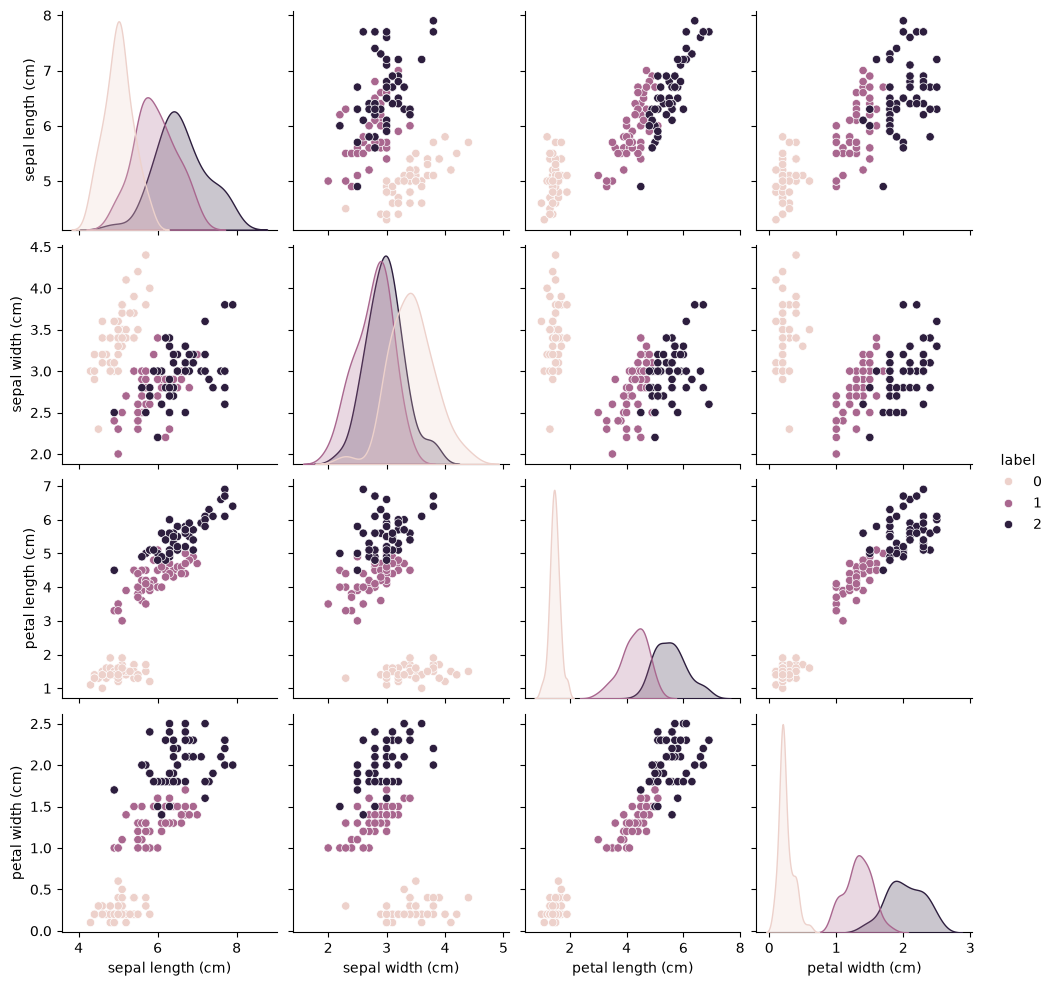

In [3]:
sns.pairplot(final, hue='label')
plt.show()

### 2.1 Train and test sets

We keep part of the data aside to check the model on flowers it has never seen.

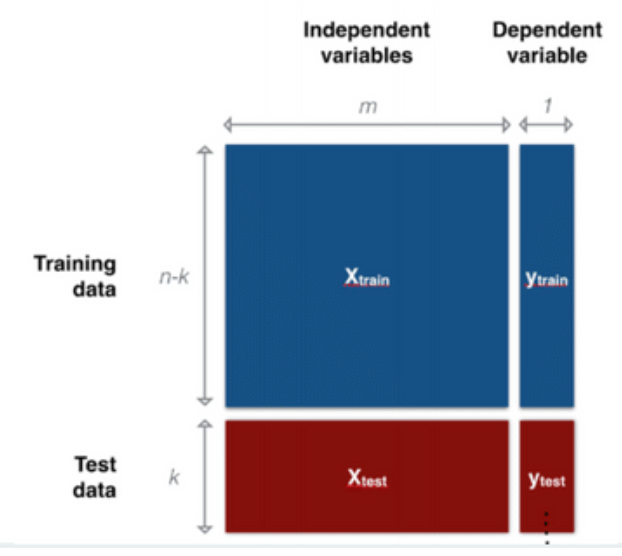

Why not just take the first 120 rows for training and the last 30 for testing?

In [4]:
final.iloc[120:150]['label'].value_counts()

label
2    30
Name: count, dtype: int64

The file is sorted by species, so the last 30 rows are all virginica. `train_test_split` shuffles first; `stratify` keeps the same share of each species in both sets, and `random_state` makes the split repeatable.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2,
                                                    stratify=labels, random_state=0)
print(X_train.shape, X_test.shape)
y_test.value_counts()

(120, 4) (30, 4)


label
0    10
1    10
2    10
Name: count, dtype: int64

### 2.2 The idea in two dimensions

A new flower appears. Which species is it? Look at its neighbours.

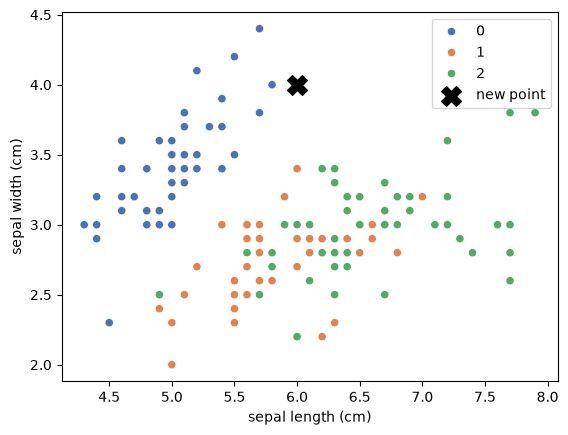

In [6]:
new_point = pd.DataFrame([[6, 4]], columns=['sepal length (cm)', 'sepal width (cm)'])

sns.scatterplot(data=final, x='sepal length (cm)', y='sepal width (cm)', hue='label', palette='deep')
plt.scatter(new_point.iloc[0, 0], new_point.iloc[0, 1], color='black', marker='X', s=200, label='new point')
plt.legend()
plt.show()

With four features we cannot draw it any more, but distance works the same way in any number of dimensions:

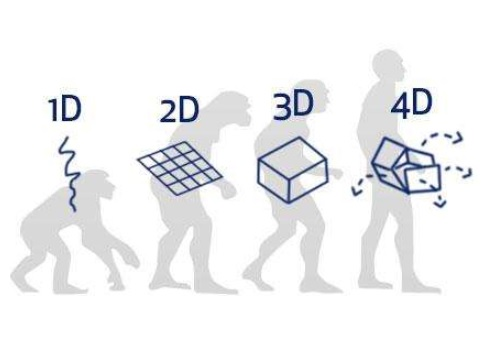

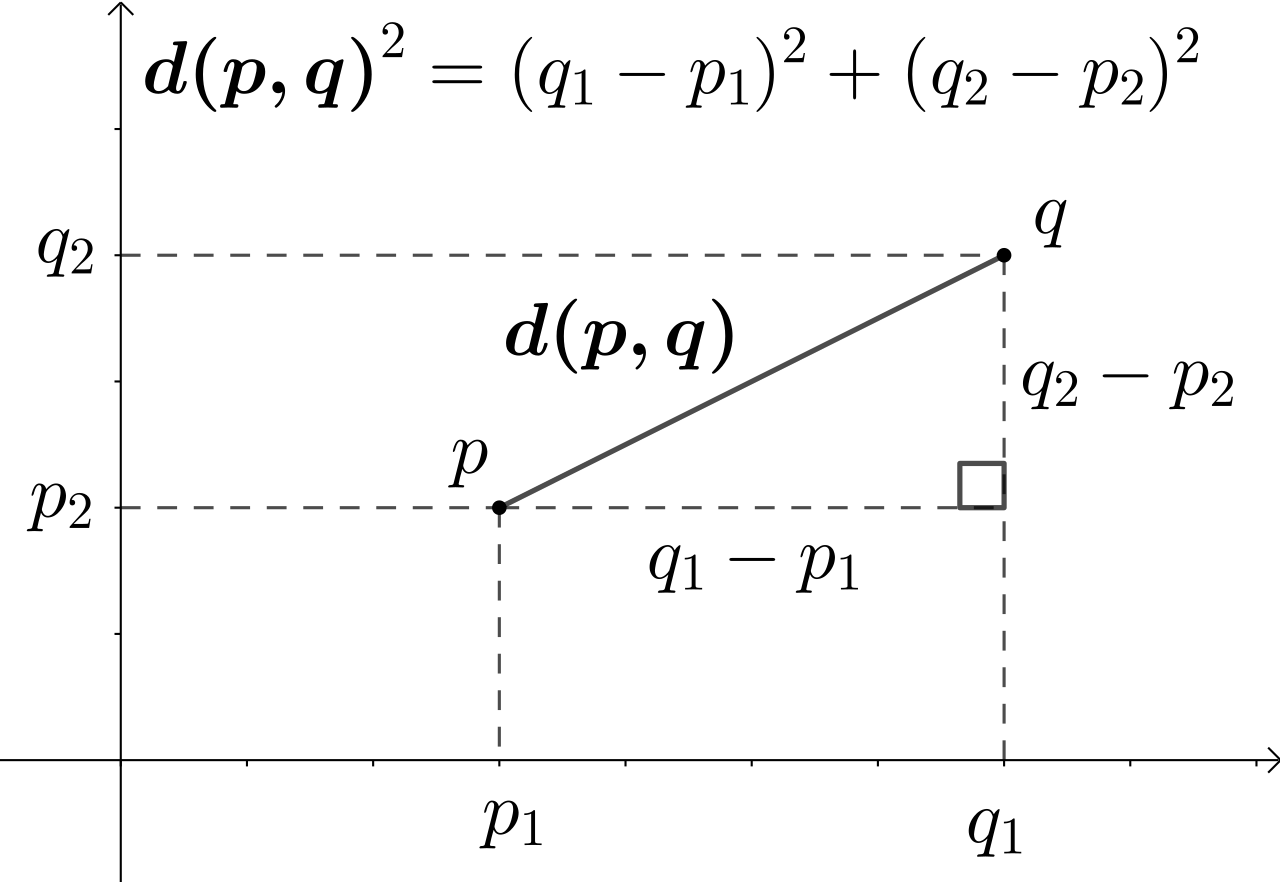

### 2.3 KNN in four dimensions, step by step

1. Compute the distance from the new point to every training point.
2. Take the `k` closest ones.
3. Give the new point the majority label among them.

In [7]:
new_point = pd.DataFrame([[6, 4, 5, 0.5]], columns=features.columns)

# Step 1: Euclidean distance to every training flower
distances = np.sqrt(((X_train - new_point.iloc[0]) ** 2).sum(axis=1))
distances.head()

45    3.929377
1     3.906405
38    4.164133
7     3.701351
82    1.852026
dtype: float64

In [8]:
# Step 2: the 5 nearest neighbours
nearest = distances.nsmallest(5)
nearest

85    1.349074
56    1.371131
91    1.407125
73    1.424781
51    1.431782
dtype: float64

In [9]:
# Step 3: majority vote among their labels
y_train.loc[nearest.index].value_counts()

label
1    5
Name: count, dtype: int64

In [10]:
y_train.loc[nearest.index].value_counts().idxmax()

np.int64(1)

## 3. The scikit-learn way: fit, predict, score

Every scikit-learn model follows the same three steps:

1. **Create** the model and choose its settings (its *hyperparameters*, here `n_neighbors`).
2. **Fit** it on the training data.
3. **Predict** on new data, and **score** it against the true labels.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

knn.predict(new_point)      # same answer as by hand

array([1])

How good is the model? Predict the test set and compare with the true labels:

In [12]:
y_pred = knn.predict(X_test)
y_pred

array([0, 1, 0, 2, 0, 1, 2, 0, 0, 1, 2, 1, 1, 2, 1, 2, 2, 1, 1, 0, 0, 2,
       2, 2, 0, 1, 1, 2, 0, 0])

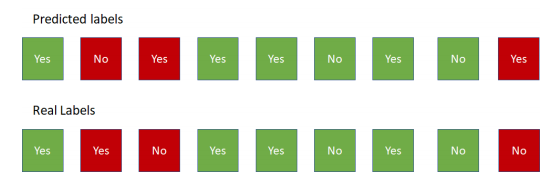

**Accuracy** is the share of correct predictions:

$$\text{accuracy} = \frac{\text{number of correct predictions}}{N}$$

In [13]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, y_pred))
print(knn.score(X_test, y_test))     # score() computes the same thing for a classifier

1.0
1.0


## 4. How scikit-learn sees data: handwritten digits

**The problem:** Consider the problem of handwritten digits recognition. Given an image of a handwritten digit we want to build a classifier that recognizes the correct label.

In [14]:
from sklearn import datasets

digits = datasets.load_digits()
X, y = digits.data, digits.target
print(X.shape, y.shape)

(1797, 64) (1797,)


Recall the formalization of the problem where the training data set consists of $N$ data pairs $S = \{(x_i,y_i)\},\; i = 1\dots N$ where $x_i \in {\bf R}^d$ is composed of $d$ features/descriptors and $y_i \in \{1,\dots,K\}$ is a discrete target label. In our current problem, we have $N = 1797$ data examples of handwritten numbers. Each sample is an $8\times 8$ image. The representation of each data sample is encoded in vector. For this reason we flatten the image and reshape it to a vector with $d=64$ corresponding to the gray values/brightness of each pixel of the image. $y_i$ is the value of the target class the number belongs to.

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


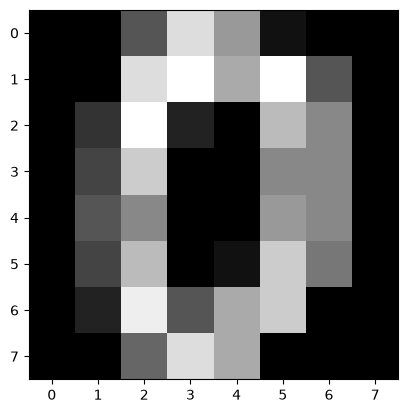

In [15]:
print(X[0].reshape(8, 8))      # the first digit, back as an 8x8 image of grey levels

plt.imshow(X[0].reshape(8, 8), cmap="gray", interpolation="nearest")
plt.show()

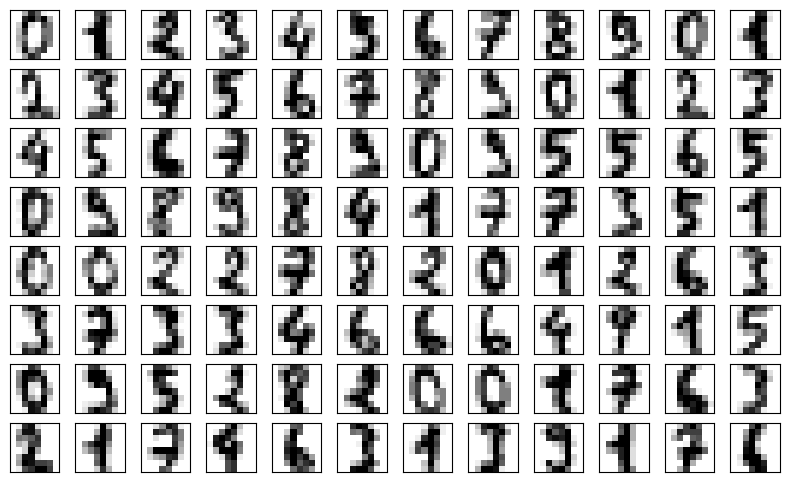

In [16]:
fig, ax = plt.subplots(8, 12, subplot_kw={'xticks': [], 'yticks': []}, figsize=(10, 6))
for i in range(ax.size):
    ax.flat[i].imshow(X[i].reshape(8, 8), cmap=plt.cm.binary)
plt.show()

A problem in Scikit-Learn is modeled as follows:

+ Input data is structured in Numpy arrays. The size of the array is expected to be [n_samples, n_features]:

    + *n_samples*: The number of samples ($N$): each sample is an item to process (e.g. classify). A sample can be a document, a picture, a sound, a video, an astronomical object, a row in database or CSV file, or whatever you can describe with a fixed set of quantitative traits.
  
    + *n_features*: The number of features ($d$) or distinct traits that can be used to describe each item in a quantitative manner. Features are generally real-valued, but may be boolean, discrete-valued or even categorical.

$${\rm feature~matrix:~~~} {\bf X}~=~\left[
\begin{matrix}
x_{11} & x_{12} & \cdots & x_{1d}\\
x_{21} & x_{22} & \cdots & x_{2d}\\
x_{31} & x_{32} & \cdots & x_{3d}\\
\vdots & \vdots & \ddots & \vdots\\
\vdots & \vdots & \ddots & \vdots\\
x_{N1} & x_{N2} & \cdots & x_{Nd}\\
\end{matrix}
\right]$$

$${\rm label~vector:~~~} {\bf y}~=~ [y_1, y_2, y_3, \cdots y_N]$$
    

The number of features must be fixed in advance. However it can be very high dimensional (e.g. millions of features) with most of them being zeros for a given sample. 

**Example** *Consider a text document representation. Given a text document we want to build a representation for it. In this case we could use as a description of the document a dictionary with all possible words in our language and create a description of the document as the number of times a certain word appears in the document. Each document is a sample and each value counting the number of times a word appear in the text is a feature. Observe that a single document will use just a handful of words. Thus there are many words not used and their representation will be zero. This is a case where scipy.sparse matrices can be useful, in that they are much more memory-efficient than numpy arrays.*

**Dataset jargon**

Considering data arranged as in the previous section we refer to:

+ the **columns** as features, attributes, dimensions, regressors, covariates, predictors, independent variables,
+ the **rows** as instances, examples, samples.
+ the **target** as label, outcome, response, dependent variable.

**Discuss with your partner:** you are asked to build something like Shazam, which recognises a song from a few seconds of audio. What could the feature vector of one sample look like?

## 5. Why we never score on the training data

Let's fit a 1-nearest-neighbour model on all the digits and score it on the same data.

In [17]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)
knn.score(X, y)

1.0

A perfect score — and a meaningless one. With `k=1`, the nearest neighbour of every training point is the point itself, so the model just remembers the answers. What we care about is how it does on data it has **not** seen.

Until now, we've evaluated our classifier's performance using the same dataset on which it was trained. While this can provide some insights into how well the model has learned the training data, it doesn't accurately represent how the model will perform on new, unseen data. In real-world applications, we expect our model to make predictions on data it has never encountered during the training phase.

**Why split?**

To simulate a more realistic scenario and better understand the model's generalization ability, we split our dataset into two separate sets:

- **Training set:** This portion of the data is used to train the model. It learns from this data, adjusting its parameters to fit the given input features to the corresponding target values.
- **Testing set:** This set is kept separate from the training process. After the model has been trained, we use this data to evaluate its performance. The testing set acts as a proxy for new, unseen data.

Splitting the data helps us to:

1. **Assess generalization:** By evaluating the model on data it hasn't seen before, we can measure how well it generalizes to new examples. This is a better indicator of its real-world performance.
2. **Detect overfitting:** If a model performs exceptionally well on the training data but poorly on the testing data, it's likely overfitting. Overfitting happens when a model learns the noise in the training data instead of the underlying pattern, making it perform poorly on any data outside the training set.
3. **Tune parameters:** The train/test split allows us to adjust the model's parameters and select the best model configuration. By comparing the model's performance on the training and testing sets, we can make informed decisions about parameter settings and model choices.

**In practice**

In practice, the dataset is randomly split into training and testing sets, often with ratios like 70%/30%, 80%/20%, or similar, depending on the dataset size and the specific problem. Tools like `train_test_split` from `sklearn.model_selection` can automate this process, ensuring that the data is randomly and appropriately divided.

By adopting this approach, we ensure that our model evaluation is more robust and indicative of how the model will perform in practical applications, thereby increasing our confidence in its predictions on unseen data.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

print('Train accuracy:', knn.score(X_train, y_train))
print('Test accuracy: ', knn.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy:  0.987037037037037


The test accuracy is the honest estimate of how the model will do on new digits.

## 6. The confusion matrix

Accuracy is one number. The **confusion matrix** shows *where* the mistakes are: each row is a true class, each column a predicted class, and every count off the diagonal is an error.

[Confusion matrix explained (StatQuest)](https://www.youtube.com/watch?v=Kdsp6soqA7o&ab_channel=StatQuestwithJoshStarmer)

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = knn.predict(X_test)
confusion_matrix(y_test, y_pred)

array([[54,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 55,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0, 53,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 55,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0, 54,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 54,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  0,  0, 54,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 54,  0,  0],
       [ 0,  3,  0,  1,  0,  0,  0,  0, 48,  0],
       [ 0,  0,  0,  0,  1,  0,  0,  0,  1, 52]])

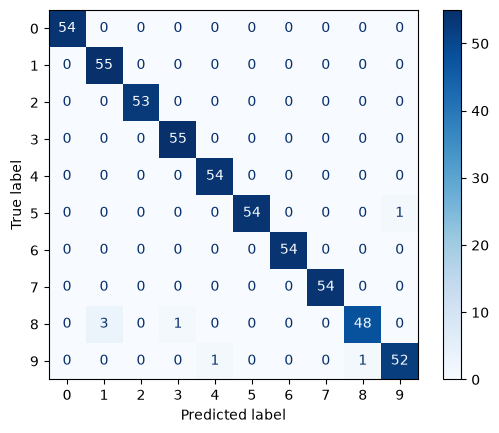

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.show()

**Question:** which digits does the model confuse most often? Does that make sense when you look at handwriting?

## 7. One split is one draw

A different random split gives a slightly different test accuracy: the test set is a sample, and samples vary (remember Day 2). Repeating the split several times shows how much.

In [21]:
acc = []
for i in range(10):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=i)
    model = KNeighborsClassifier(n_neighbors=1).fit(X_tr, y_tr)
    acc.append(model.score(X_te, y_te))

acc = np.array(acc)
print(acc.round(3))
print(f'Mean {acc.mean():.3f}, std {acc.std():.3f}')

[0.983 0.985 0.985 0.985 0.991 0.983 0.981 0.989 0.981 0.978]
Mean 0.984, std 0.004


## 8. Train, validation and test: choosing k

`k` is a **hyperparameter**: we choose it, the model does not learn it. To choose it fairly we need a third set.

- **Training set:** the model learns from it.
- **Validation set:** we compare settings on it and pick the best.
- **Test set:** used **once**, at the very end, to report how the chosen model does.

If we picked `k` by looking at the test score, the test set would stop being "unseen" and the final number would be too optimistic.

The digits are almost too easy for KNN: `k=1` already wins. To see the trade-off we switch to a noisier toy problem, two interleaved half-moons with overlapping points.

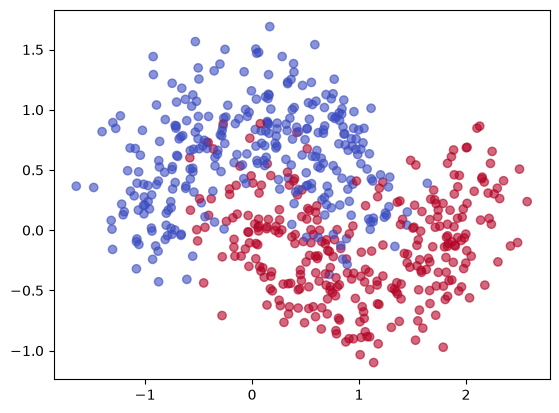

In [22]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=600, noise=0.3, random_state=0)

plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap='coolwarm', alpha=0.6)
plt.show()

In [23]:
# 60% train, 20% validation, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(X_moons, y_moons, test_size=0.2, stratify=y_moons, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(360, 2) (120, 2) (120, 2)


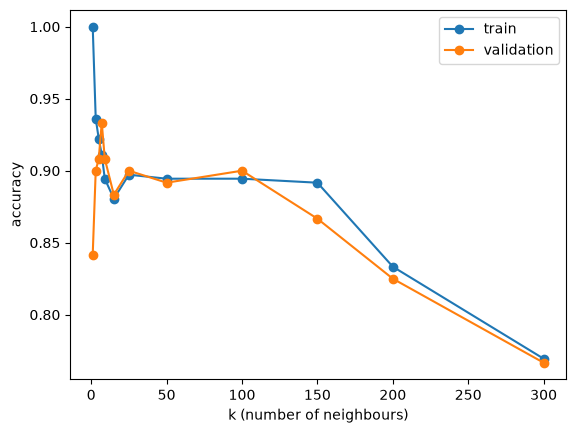

7

In [24]:
ks = [1, 3, 5, 7, 9, 15, 25, 50, 100, 150, 200, 300]
train_scores, val_scores = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    val_scores.append(model.score(X_val, y_val))

plt.plot(ks, train_scores, 'o-', label='train')
plt.plot(ks, val_scores, 'o-', label='validation')
plt.xlabel('k (number of neighbours)')
plt.ylabel('accuracy')
plt.legend()
plt.show()

best_k = ks[int(np.argmax(val_scores))]
best_k

With `k=1` the model is perfect on training data but much worse on validation: it follows the noise (**overfitting**). With very large `k` it averages over so many neighbours that it blurs the two moons, and both scores drop (**underfitting**). The best `k` sits in between.

Only now do we touch the test set, once, with the chosen `k`, trained on train and validation together:

In [25]:
final_model = KNeighborsClassifier(n_neighbors=best_k).fit(X_temp, y_temp)
final_model.score(X_test, y_test)

0.925

## 9. Cross-validation

A single validation set is still one draw. **K-fold cross-validation** splits the training data into K parts (folds), trains on K−1 of them and validates on the remaining one, K times, so every row is used for validation exactly once. The average over the folds is a steadier estimate. You will go deeper into it next week.

In [26]:
from sklearn.model_selection import cross_val_score

for k in [1, 7, 25, 100]:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_temp, y_temp, cv=5)
    print(f'k={k}: mean {scores.mean():.3f}, std {scores.std():.3f}')

k=1: mean 0.871, std 0.032
k=7: mean 0.890, std 0.014
k=25: mean 0.898, std 0.012
k=100: mean 0.892, std 0.018


Cross-validation agrees that `k=1` is the worst choice, but it rates the middle values almost the same, and slightly prefers a larger `k` than the single validation split did. One validation set is one draw; the folds average that luck out.

## 10. Saving and loading a model

A trained model is a Python object. `pickle` writes it to a file so another notebook or an app can load it and predict without retraining.

In [27]:
import pickle

with open('my_classifier.pkl', 'wb') as f:
    pickle.dump(final_model, f)

with open('my_classifier.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

loaded_model.predict(X_test[:5]), y_test[:5]

(array([0, 0, 1, 1, 1]), array([0, 0, 1, 1, 1]))

### Summary: the scikit-learn estimator interface

Every scikit-learn model shares the same few methods:

- `model.fit(X, y)`: learn from the training data. Unsupervised models take only `X`.
- `model.predict(X_new)`: predict labels (or values) for new data.
- `model.predict_proba(X_new)`: for classifiers, the probability of each class. `predict` returns the most probable one.
- `model.score(X, y)`: the default metric — accuracy for classifiers, R² for regressors.
- `model.transform(X)` / `model.fit_transform(X)`: for transformers such as scalers, which change the data rather than predict.

## Appendix

Practice and extra material. None of it is taught live.

### A.1 Feature extraction: describing a digit with three numbers

When we work with data, especially in machine learning, we often start with raw values. In our case, we're dealing with images of digits, and the raw values are the gray levels of each pixel in these images. To make sense of this data and potentially improve how we distinguish between different digits, we can extract or derive new features from the raw data. These features are characteristics we compute from the data, based on our understanding of what might be important to identify the differences between classes (in this case, different digit types).

#### Derived Features: Symmetry and Area

For the digits dataset, we consider three specific features that might help us differentiate between digits:

- **Horizontal Symmetry**: How similar is the left half of the image to the right half?
- **Vertical Symmetry**: How similar is the top half of the image to the bottom half?
- **Area**: The sum of all pixel values, which can be thought of as the "weight" of the digit.

First, a digit and its horizontal mirror:

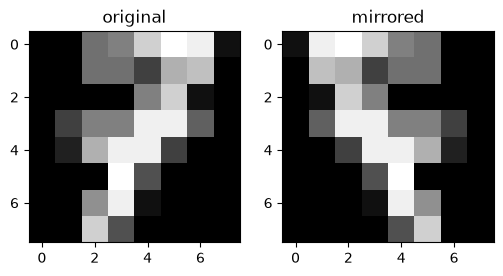

In [28]:
tmp = X[7].reshape((8, 8))

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(tmp, cmap='gray'); ax[0].set_title('original')
ax[1].imshow(tmp[:, ::-1], cmap='gray'); ax[1].set_title('mirrored')
plt.show()

Now compute the three features for every digit:

In [29]:
Xnew = np.zeros((y.shape[0], 3))

for i in range(y.shape[0]):
    tmp = X[i].reshape((8, 8))
    area = X[i].sum()
    symH = (tmp * tmp[:, ::-1]).sum()   # horizontal symmetry
    symV = (tmp * tmp[::-1, :]).sum()   # vertical symmetry
    Xnew[i, :] = [symH, area, symV]

print(Xnew.shape)

(1797, 3)


How do digits 0 and 6 look in this new feature space?

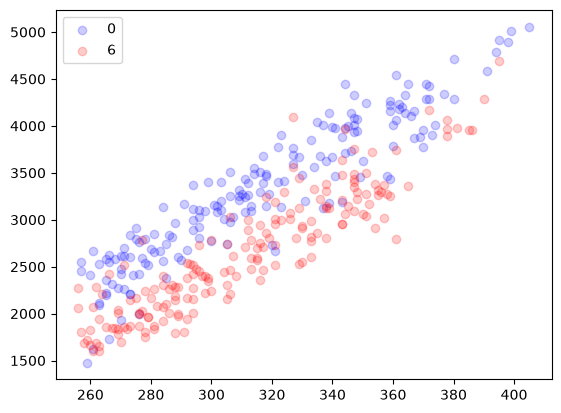

In [30]:
feature1, feature2 = 1, 2   # 0 = horizontal symmetry, 1 = area, 2 = vertical symmetry

plt.scatter(Xnew[y == 0, feature1], Xnew[y == 0, feature2], c='blue', alpha=0.2, label='0')
plt.scatter(Xnew[y == 6, feature1], Xnew[y == 6, feature2], c='red', alpha=0.2, label='6')
plt.legend()
plt.show()

**Exercise:** change `feature1` and `feature2` (0, 1 or 2) and find the view that separates the two digits best. Why that one?

Using domain knowledge to build discriminant features like these is called **feature extraction**.

When working with machine learning models, we often encounter two primary approaches to preparing our data: using raw data directly or extracting features from this data. Both approaches have their advantages and drawbacks, which are crucial to understand for effective model development.

**Raw data**

**Advantages:**

- **Accessibility:** Raw data can be used directly without the need for additional processing or transformation. This approach does not require domain-specific knowledge, making it straightforward and accessible to practitioners at all levels.

**Drawbacks:**

- **Redundancy and Dimensionality:** Raw data is often highly redundant, containing information that may not be necessary for making accurate predictions or classifications. This redundancy typically results in very large dimensional spaces, which can complicate model training and lead to longer computation times.
- **Unknown Discriminability:** With raw data, it's not always clear which features are important for distinguishing between classes. This lack of clarity can hinder a model's ability to learn effectively, as it may focus on irrelevant features.

**Feature extraction**

**Advantages:**

- **Discriminant Information:** Feature extraction aims to identify and capture the most relevant information in the data for the task at hand. By focusing on discriminant information, models can often achieve better performance with less data.
- **Reduced Dimensionality and Complexity:** Through feature extraction, data is transformed into a lower-dimensional space that reflects the most important aspects of the original data. This reduction in dimensionality and complexity can lead to faster training times and more efficient models.

**Drawbacks:**

- **Domain Knowledge Required:** Unlike using raw data, feature extraction often requires domain-specific knowledge to identify which features are likely to be informative. This requirement can make feature extraction less accessible to those without expertise in the domain.

### A.2 Comparing models: repeated splits and k-fold

The same comparison as sections 7 and 9, across four models on the three extracted features. You meet SVMs and decision trees tomorrow.

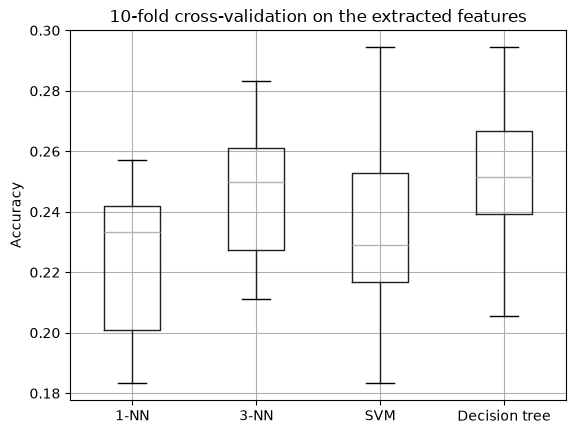

1-NN             0.224
3-NN             0.245
SVM              0.236
Decision tree    0.253
dtype: float64

In [31]:
from sklearn import svm, tree
from sklearn.model_selection import KFold

models = {'1-NN': KNeighborsClassifier(n_neighbors=1),
          '3-NN': KNeighborsClassifier(n_neighbors=3),
          'SVM': svm.SVC(),
          'Decision tree': tree.DecisionTreeClassifier(random_state=0)}

kf = KFold(n_splits=10, shuffle=True, random_state=0)
cv_acc = pd.DataFrame({name: cross_val_score(m, Xnew, y, cv=kf) for name, m in models.items()})

cv_acc.boxplot()
plt.ylabel('Accuracy')
plt.title('10-fold cross-validation on the extracted features')
plt.show()
cv_acc.mean().round(3)

Three hand-made features are far less informative than the 64 raw pixels: compare these accuracies with section 5.

### A.3 In-sample and out-of-sample error

In the realm of machine learning and statistical learning theory, it's essential to quantify the performance of our models. To do this, we introduce specific nomenclature for the error metrics we compute during model training and evaluation.

#### In-Sample Error ($E_{\text{in}}$)

- **Definition:** The in-sample error, also known as the training error, measures the error over all observed data samples within the training set. It reflects how well the model fits the data it was trained on.
- **Formula:** The mathematical representation is given by:

  $$E_{\text{in}} = \frac{1}{N}\sum\limits_{i=1}^{N} e(x_i,y_i)$$

  where $N$ is the number of samples in the training set, and $e(x_i,y_i)$ denotes the error of the prediction on the $i$-th sample.

#### Out-of-Sample Error ($E_{\text{out}}$)

- **Definition:** The out-of-sample error, or generalization error, measures the expected error on unseen data. This metric is crucial as it indicates the model's ability to generalize beyond the training data.
- **Approximation:** We approximate $E_{\text{out}}$ by holding out a portion of the training data for testing purposes, thus not exposing the model to this data during training.

  $$E_{\text{out}}=\mathbb{E}_{x,y}(e(x,y))$$

  Here, the expectation $\mathbb{E}_{x,y}$ reflects the average error over all possible unseen samples.

#### Instantaneous Error ($e(x_i,y_i)$)

- **Definition:** To measure the error for individual predictions, we define the instantaneous error. This metric assesses the error on a single data point.
- **Example:** In the context of classification, we might use the indicator function to evaluate whether a sample is correctly classified:

  $$e(x_i,y_i) = I[h(x_i)=y_i] =\left\{
  \begin{align}
  1 & \text{ if } h(x_i)=y_i\\
  0 & \text{ otherwise } \\
  \end{align}
  \right.$$

  where $h(x_i)$ is the predicted label for sample $x_i$, and $y_i$ is the true label.

#### Understanding the Relationship Between $E_{\text{in}}$ and $E_{\text{out}}$

It's a fundamental principle that the out-of-sample error is expected to be greater than or equal to the in-sample error:

$$E_{\text{out}} \geq E_{\text{in}}$$

This inequality underscores the challenge of overfitting, where a model might perform exceptionally well on the training data ($E_{\text{in}}$ is low) but poorly on new, unseen data ($E_{\text{out}}$ is high). The primary goal in model training is to minimize $E_{\text{out}}$, ensuring that our model generalizes well to new data.